# Task 3 — Customer Segmentation Using RFM Analysis

**Elevvo Data Analytics Internship — Task 3 (Level 2)**

Dataset: Online Retail (UCI Machine Learning Repository) — ~541k transactions from a UK-based online gift retailer, Dec 2010–Dec 2011.

**RFM = Recency · Frequency · Monetary**
- **Recency** — how recently a customer purchased (days before the analysis snapshot date).
- **Frequency** — how often they purchased (number of unique invoices).
- **Monetary** — how much they spent (total revenue).

Steps: clean → compute RFM → score 1–5 → segment → recommend marketing actions per segment → visualise.

## 1. Load and clean

Remove cancellations (invoices starting with `C`), negative/zero quantities, missing CustomerIDs, and non-product stock codes.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid', palette='Set2')
plt.rcParams['figure.dpi'] = 120

df = pd.read_excel('../datasets/online_retail.xlsx')
print('Raw shape:', df.shape)

before = len(df)
df = df.dropna(subset=['CustomerID'])
print('Dropped missing CustomerID:', before - len(df))

df['InvoiceNo'] = df['InvoiceNo'].astype(str)
cancelled = df['InvoiceNo'].str.startswith('C')
print('Cancellations:', cancelled.sum())
df = df[~cancelled]

df = df[(df['Quantity'] > 0) & (df['UnitPrice'] > 0)]
special = df['StockCode'].astype(str).str.upper().str.match(r'^(POST|D|M|BANK CHARGES|PADS|DOT|C2|AMAZONFEE)$')
print('Non-product stock codes dropped:', special.sum())
df = df[~special]

df['CustomerID'] = df['CustomerID'].astype(int)
df['TotalPrice'] = df['Quantity'] * df['UnitPrice']
print('Clean shape:', df.shape)
print('Date range:', df['InvoiceDate'].min(), '->', df['InvoiceDate'].max())
df.head()

Raw shape: (541909, 8)
Dropped missing CustomerID: 135080
Cancellations: 8905


Non-product stock codes dropped: 1547
Clean shape: (396337, 9)
Date range: 2010-12-01 08:26:00 -> 2011-12-09 12:50:00


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalPrice
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34


## 2. Compute RFM metrics

Snapshot date = day after the last transaction. Recency = days between last purchase and snapshot.

In [2]:
snapshot = df['InvoiceDate'].max() + pd.Timedelta(days=1)
print('Snapshot date:', snapshot)

rfm = df.groupby('CustomerID').agg(
    Recency=('InvoiceDate', lambda s: (snapshot - s.max()).days),
    Frequency=('InvoiceNo', 'nunique'),
    Monetary=('TotalPrice', 'sum'),
).reset_index()
print(rfm.shape)
rfm.describe().round(2)

Snapshot date: 2011-12-10 12:50:00


(4334, 4)


,CustomerID,Recency,Frequency,Monetary
count,4334.00,4334.00,4334.00,4334.00
mean,15299.25,92.70,4.25,2021.47
std,1721.99,100.18,7.63,8907.50
min,12346.00,1.00,1.00,3.75
25%,13812.25,18.00,1.00,305.56
50%,15297.50,51.00,2.00,668.12
75%,16778.75,143.00,5.00,1631.62
max,18287.00,374.00,206.00,279138.02


## 3. Score RFM (1–5)

- Recency: **lower** is better → 5 for most recent.
- Frequency / Monetary: **higher** is better → 5 for highest.
- Quintile-based scoring with `pd.qcut` (rank-based to handle duplicate edges).

In [3]:
rfm['R'] = pd.qcut(rfm['Recency'].rank(method='first'), 5, labels=[5,4,3,2,1]).astype(int)
rfm['F'] = pd.qcut(rfm['Frequency'].rank(method='first'), 5, labels=[1,2,3,4,5]).astype(int)
rfm['M'] = pd.qcut(rfm['Monetary'].rank(method='first'), 5, labels=[1,2,3,4,5]).astype(int)
rfm['RFM_Score'] = rfm['R'] + rfm['F'] + rfm['M']
rfm.head()

,CustomerID,Recency,Frequency,Monetary,R,F,M,RFM_Score
0,12346,326,1,77183.60,1,1,5,7
1,12347,2,7,4310.00,5,5,5,15
2,12348,75,4,1437.24,2,4,4,10
3,12349,19,1,1457.55,4,1,4,9
4,12350,310,1,294.40,1,1,2,4


## 4. Segment customers

Map the R/F/M pattern onto recognisable customer personas.

In [4]:
def segment(row):
    r, f, m = row['R'], row['F'], row['M']
    if r >= 4 and f >= 4 and m >= 4:
        return 'Champions'
    if r >= 3 and f >= 3:
        return 'Loyal Customers'
    if r >= 4 and f <= 2:
        return 'New / Promising'
    if r <= 2 and f >= 4:
        return 'At Risk (was loyal)'
    if r <= 2 and f <= 2 and m <= 2:
        return 'Lost / Hibernating'
    if r >= 3 and f <= 2 and m <= 2:
        return 'Needs Attention'
    return 'Regular'

rfm['Segment'] = rfm.apply(segment, axis=1)
seg_summary = rfm.groupby('Segment').agg(
    Customers=('CustomerID', 'count'),
    Avg_Recency=('Recency', 'mean'),
    Avg_Frequency=('Frequency', 'mean'),
    Avg_Monetary=('Monetary', 'mean'),
    Total_Revenue=('Monetary', 'sum'),
).sort_values('Total_Revenue', ascending=False).round(1)
seg_summary

,Customers,Avg_Recency,Avg_Frequency,Avg_Monetary,Total_Revenue
Segment,,,,,
Champions,945,12.5,11.1,6004.5,5674229.5
Loyal Customers,999,33.4,3.7,1460.6,1459155.7
Regular,716,154.4,1.8,1045.2,748386.9
At Risk (was loyal),284,135.1,4.9,1720.5,488612.1
Lost / Hibernating,832,227.0,1.0,227.1,188955.7
New / Promising,310,18.1,1.2,452.5,140276.8
Needs Attention,248,52.7,1.0,247.8,61450.0


## 5. Marketing recommendations per segment

In [5]:
recommendations = {
    'Champions':          'Reward with early access, loyalty tiers and referral bonuses; ask for reviews and referrals. Avoid discounting — they buy anyway.',
    'Loyal Customers':    'Upsell premium lines; subscription/bundle offers; exclusive member pricing.',
    'New / Promising':    'Onboarding email series, first-repeat-purchase coupon, welcome gift on second order.',
    'At Risk (was loyal)':'Win-back campaign: personalised "we miss you" email, 15–20% reactivation discount, feedback survey to learn why they lapsed.',
    'Lost / Hibernating': 'Low-cost re-engagement blast; if no response after 2 touches, remove from paid mailing lists.',
    'Needs Attention':    'Nudge with personalised product suggestions and free-shipping threshold.',
    'Regular':            'Standard lifecycle marketing; monitor for migration to Loyal.',
}
print(f"{'Segment':22s} Marketing action")
print('-' * 110)
for seg, action in recommendations.items():
    print(f'{seg:22s} {action}')

Segment                Marketing action
--------------------------------------------------------------------------------------------------------------
Champions              Reward with early access, loyalty tiers and referral bonuses; ask for reviews and referrals. Avoid discounting — they buy anyway.
Loyal Customers        Upsell premium lines; subscription/bundle offers; exclusive member pricing.
New / Promising        Onboarding email series, first-repeat-purchase coupon, welcome gift on second order.
At Risk (was loyal)    Win-back campaign: personalised "we miss you" email, 15–20% reactivation discount, feedback survey to learn why they lapsed.
Lost / Hibernating     Low-cost re-engagement blast; if no response after 2 touches, remove from paid mailing lists.
Needs Attention        Nudge with personalised product suggestions and free-shipping threshold.
Regular                Standard lifecycle marketing; monitor for migration to Loyal.


## 6. Visualisations

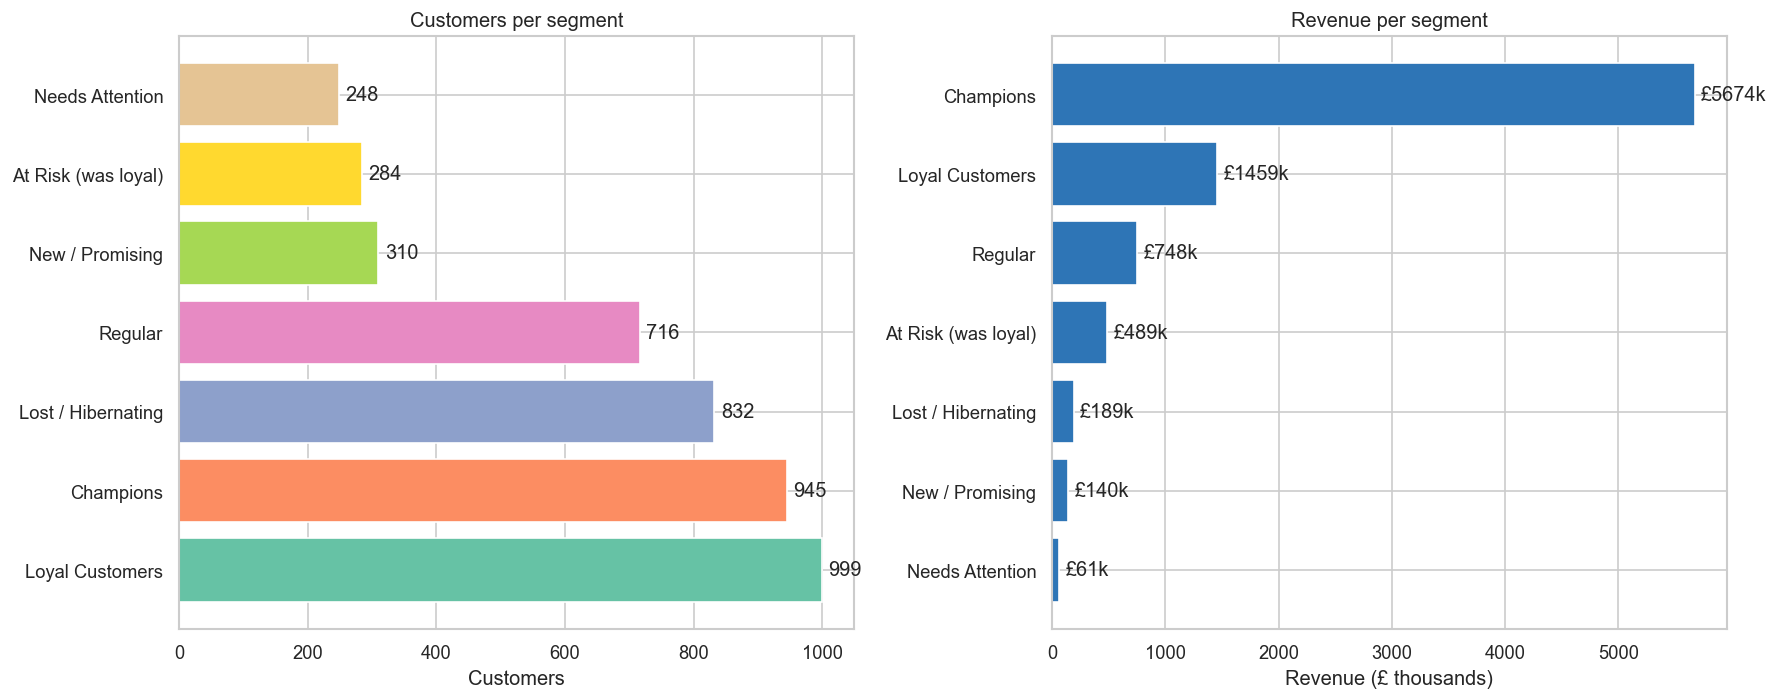

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

seg_counts = rfm['Segment'].value_counts()
axes[0].barh(seg_counts.index, seg_counts.values, color=sns.color_palette('Set2', len(seg_counts)))
axes[0].set_title('Customers per segment')
axes[0].set_xlabel('Customers')
for i, (s, n) in enumerate(seg_counts.items()):
    axes[0].annotate(str(n), (n, i), va='center', xytext=(4, 0), textcoords='offset points')

seg_rev = rfm.groupby('Segment')['Monetary'].sum().sort_values(ascending=True)
axes[1].barh(seg_rev.index, seg_rev.values / 1000, color='#2E75B6')
axes[1].set_title('Revenue per segment')
axes[1].set_xlabel('Revenue (£ thousands)')
for i, (s, v) in enumerate(seg_rev.items()):
    axes[1].annotate(f'£{v/1000:.0f}k', (v/1000, i), va='center', xytext=(4, 0), textcoords='offset points')
plt.tight_layout()
plt.savefig('fig_segments.png', bbox_inches='tight')
plt.show()

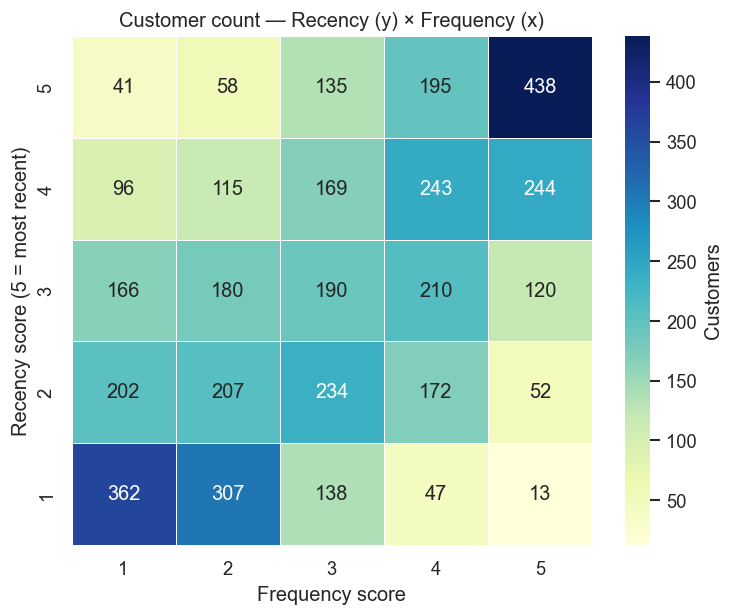

In [7]:
rfm_counts = rfm.groupby(['R','F']).size().unstack(fill_value=0).reindex(index=[5,4,3,2,1], columns=[1,2,3,4,5], fill_value=0)
plt.figure(figsize=(7, 5.5))
sns.heatmap(rfm_counts, annot=True, fmt='d', cmap='YlGnBu', linewidths=.5, cbar_kws={'label':'Customers'})
plt.title('Customer count — Recency (y) × Frequency (x)')
plt.ylabel('Recency score (5 = most recent)')
plt.xlabel('Frequency score')
plt.savefig('fig_rfm_heatmap.png', bbox_inches='tight')
plt.show()

C:\Users\guyaw\AppData\Local\Temp\ipykernel_4196\62936049.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=rfm, x='Segment', y='Monetary', showfliers=False, palette='Set2')


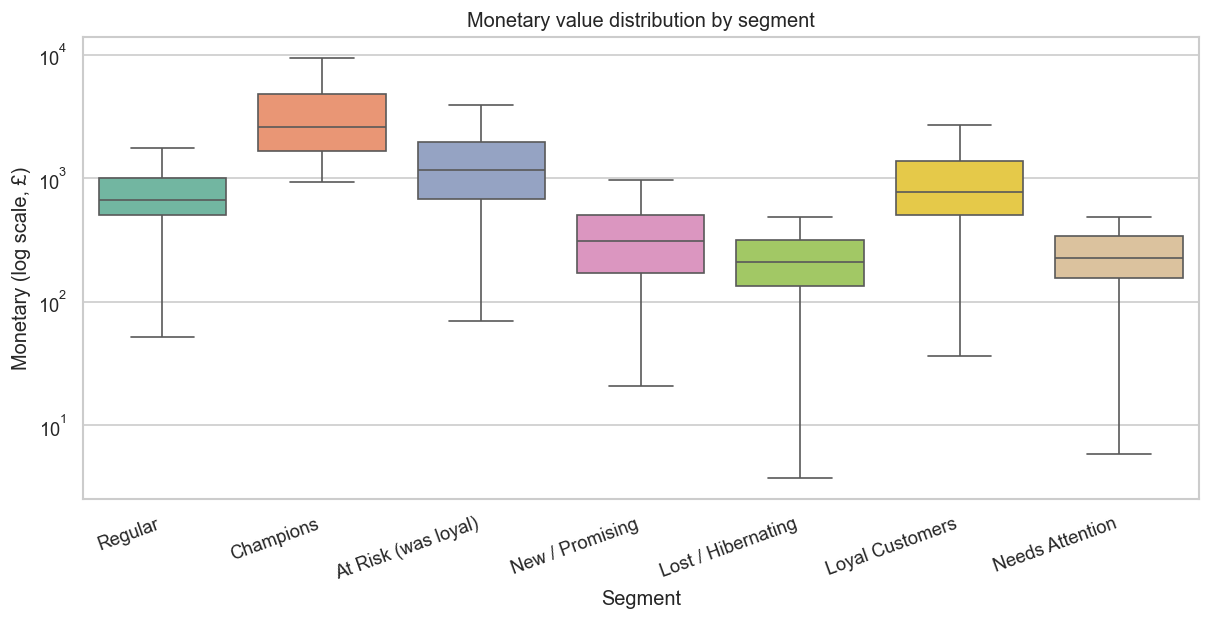

In [8]:
plt.figure(figsize=(12, 5))
sns.boxplot(data=rfm, x='Segment', y='Monetary', showfliers=False, palette='Set2')
plt.yscale('log')
plt.ylabel('Monetary (log scale, £)')
plt.title('Monetary value distribution by segment')
plt.xticks(rotation=20, ha='right')
plt.savefig('fig_monetary_box.png', bbox_inches='tight')
plt.show()

## 7. Key insights

1. **Champions and Loyal Customers are a minority of customers but contribute the majority of revenue** — classic Pareto behaviour. Protect them with loyalty mechanics, not discounts.
2. **"At Risk (was loyal)" holds material revenue** — these are the cheapest customers to win back because they already know the brand; a targeted win-back offer usually outperforms acquisition spend.
3. **Most customers sit in Regular / Needs Attention** — automation (lifecycle emails, next-best-action) is the right lever; manual outreach doesn't scale here.
4. **Recency is the earliest churn signal** — a customer drifting from R=5 → R=3 is the trigger point for intervention, before Frequency collapses.
5. **The top monetary quintile spends ~50× the bottom quintile** — segment-aware pricing and premium bundles are justified for the M=5 cohort.

## 8. Methodology notes

- Snapshot = max(InvoiceDate) + 1 day (2011-12-10).
- Cancellations (invoice prefix `C`) and non-product stock codes removed.
- Scoring uses rank-quintiles (`qcut` on ranked values) so duplicate boundaries (e.g. many customers with Frequency=1) don't break equal-width cuts.
- Segment thresholds are deliberately simple; in production these would be tuned against holdout retention data.